# 04 - Fine-tuning (last blocks + head)

**Goal:** start from the best head-only checkpoint from notebook 03, then fine-tune the last MobileNetV3 blocks at a lower learning rate.

This notebook runs multiple seeds and keeps the best run by validation loss.


In [1]:
import json, random, time, shutil
from pathlib import Path

import numpy as np
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from torchvision import transforms
from torchvision.models import mobilenet_v3_small, MobileNet_V3_Small_Weights
import torch_directml


In [5]:

PROJECT_ROOT = Path.cwd().parent
ARTIFACTS = PROJECT_ROOT / "agrilens-training/artifacts"
ARTIFACTS.mkdir(exist_ok=True)

dml = torch_directml.device()
print("DirectML device:", torch_directml.device_name(0))
print("Torch:", torch.__version__)


DirectML device: AMD Radeon RX 5700 
Torch: 2.4.1+cpu


In [6]:
def seed_everything(seed: int):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)


### Step 1 - load split manifest and previous training artifacts

In [7]:
class_map_path = ARTIFACTS / "class_map.json"
manifest_path = ARTIFACTS / "manifest_v2.csv"
preprocess_path = ARTIFACTS / "preprocess_contract.json"
head_ckpt_path = ARTIFACTS / "mobilenetv3_head_best.pt"
head_report_path = ARTIFACTS / "head_training_report.json"

for p in [class_map_path, manifest_path, preprocess_path, head_ckpt_path]:
    if not p.exists():
        raise FileNotFoundError(f"Missing required artifact: {p}")

class_map = json.loads(class_map_path.read_text(encoding="utf-8"))
labels = [c["label"] for c in sorted(class_map, key=lambda x: x["id"])]
num_classes = len(labels)

preprocess = json.loads(preprocess_path.read_text(encoding="utf-8"))
input_size = int(preprocess["input_size"])
mean = preprocess["mean"]
std = preprocess["std"]

df = pd.read_csv(manifest_path)
df["class_id"] = df["class_id"].astype(int)
df["split"] = df["split"].astype(str).str.lower()
allowed = {"train", "val", "test"}
bad = sorted(set(df["split"]) - allowed)
if bad:
    raise ValueError(f"Unexpected split values: {bad}")

for s in ["train", "val", "test"]:
    if (df["split"] == s).sum() == 0:
        raise ValueError(f"Split {s} has zero rows")

print("rows:", len(df))
print(df.groupby(["split", "class_id"]).size().unstack(fill_value=0))

head_report = None
if head_report_path.exists():
    head_report = json.loads(head_report_path.read_text(encoding="utf-8"))
    print("loaded:", head_report_path.name)


rows: 11431
class_id    0    1    2    3     4    5     6    7     8
split                                                   
test      179  148   77  174   319  150   286  143   238
train     834  689  359  814  1489  700  1336  666  1114
val       179  148   77  174   319  150   287  143   239
loaded: head_training_report.json


### Step 2 - datasets and dataloaders

In [8]:
train_tfms = transforms.Compose([
    transforms.Resize((input_size, input_size)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=10),
    transforms.ColorJitter(brightness=0.10, contrast=0.10, saturation=0.08, hue=0.02),
    transforms.ToTensor(),
    transforms.Normalize(mean=mean, std=std),
])

eval_tfms = transforms.Compose([
    transforms.Resize((input_size, input_size)),
    transforms.ToTensor(),
    transforms.Normalize(mean=mean, std=std),
])

class LeafDataset(Dataset):
    def __init__(self, frame: pd.DataFrame, tfm):
        self.frame = frame.reset_index(drop=True)
        self.tfm = tfm

    def __len__(self):
        return len(self.frame)

    def __getitem__(self, idx):
        row = self.frame.iloc[idx]
        img = Image.open(row.path).convert("RGB")
        x = self.tfm(img)
        y = int(row.class_id)
        return x, y

train_df = df[df.split == "train"].copy()
val_df = df[df.split == "val"].copy()
test_df = df[df.split == "test"].copy()

train_ds = LeafDataset(train_df, train_tfms)
val_ds = LeafDataset(val_df, eval_tfms)
test_ds = LeafDataset(test_df, eval_tfms)

BATCH_SIZE = 32
NUM_WORKERS = 0

train_counts = train_df["class_id"].value_counts().sort_index()
count_arr = np.array([train_counts.get(i, 0) for i in range(num_classes)], dtype=np.float64)
if np.any(count_arr == 0):
    raise ValueError("At least one class has zero train rows.")

if head_report and "class_weights" in head_report:
    class_weights_np = np.array(head_report["class_weights"], dtype=np.float64)
else:
    class_weights_np = count_arr.sum() / (num_classes * count_arr)
    class_weights_np = class_weights_np / class_weights_np.mean()

IMBALANCE_MODE = head_report["imbalance_mode"] if (head_report and "imbalance_mode" in head_report) else "class_weighted_loss"
class_weights = torch.tensor(class_weights_np, dtype=torch.float32, device=dml)

if IMBALANCE_MODE == "weighted_sampler":
    sample_w = train_df["class_id"].map(lambda c: class_weights_np[int(c)]).astype(np.float64).to_numpy()
    sampler = WeightedRandomSampler(weights=sample_w, num_samples=len(sample_w), replacement=True)
    train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, sampler=sampler, num_workers=NUM_WORKERS)
    loss_fn = nn.CrossEntropyLoss()
else:
    train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS)
    loss_fn = nn.CrossEntropyLoss(weight=class_weights)

val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS)
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS)

print("imbalance mode:", IMBALANCE_MODE)
print("class weights:", np.round(class_weights_np, 3).tolist())


imbalance mode: class_weighted_loss
class weights: [0.906, 1.097, 2.105, 0.928, 0.507, 1.079, 0.566, 1.134, 0.678]


### Step 3 - model helpers (load head checkpoint, unfreeze last blocks)

In [9]:
UNFREEZE_LAST_BLOCKS = 4
BACKBONE_LR = 1e-4
HEAD_LR = 3e-4
WEIGHT_DECAY = 1e-4

def build_model_from_head_checkpoint(head_ckpt: Path):
    model = mobilenet_v3_small(weights=MobileNet_V3_Small_Weights.IMAGENET1K_V1)
    model.classifier[3] = nn.Linear(model.classifier[3].in_features, num_classes)

    ckpt = torch.load(head_ckpt, map_location="cpu")
    state = ckpt["state_dict"] if isinstance(ckpt, dict) and "state_dict" in ckpt else ckpt
    model.load_state_dict(state)

    for p in model.features.parameters():
        p.requires_grad = False
    for p in model.classifier.parameters():
        p.requires_grad = True

    if UNFREEZE_LAST_BLOCKS > 0:
        for block in model.features[-UNFREEZE_LAST_BLOCKS:]:
            for p in block.parameters():
                p.requires_grad = True

    model = model.to(dml)

    backbone_params = []
    head_params = []
    for name, p in model.named_parameters():
        if not p.requires_grad:
            continue
        if name.startswith("classifier"):
            head_params.append(p)
        else:
            backbone_params.append(p)

    optimizer = torch.optim.AdamW(
        [
            {"params": backbone_params, "lr": BACKBONE_LR},
            {"params": head_params, "lr": HEAD_LR},
        ],
        weight_decay=WEIGHT_DECAY,
    )
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    total = sum(p.numel() for p in model.parameters())
    print(f"trainable params: {trainable:,} / {total:,}")
    return model, optimizer

@torch.no_grad()
def evaluate(model, loader):
    model.eval()
    n, correct, loss_sum = 0, 0, 0.0
    for xb, yb in loader:
        xb = xb.to(dml)
        yb = yb.to(dml)
        logits = model(xb)
        loss = loss_fn(logits, yb)
        bs = yb.shape[0]
        loss_sum += float(loss.item()) * bs
        correct += int((logits.argmax(1) == yb).sum().item())
        n += bs
    return {"loss": loss_sum / max(n, 1), "acc": correct / max(n, 1)}


### Step 4 - run fine-tuning across seeds

In [10]:
SEEDS = [7, 42, 123]
EPOCHS = 12
PATIENCE = 3

seed_rows = []
all_histories = []

for seed in SEEDS:
    print("\n=== seed", seed, "===")
    seed_everything(seed)

    model, optimizer = build_model_from_head_checkpoint(head_ckpt_path)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)

    best_val_loss = float("inf")
    best_epoch = -1
    patience_left = PATIENCE
    history = []

    best_path = ARTIFACTS / f"mobilenetv3_finetune_seed{seed}_best.pt"
    last_path = ARTIFACTS / f"mobilenetv3_finetune_seed{seed}_last.pt"

    for epoch in range(1, EPOCHS + 1):
        t0 = time.perf_counter()
        model.train()
        tr_n, tr_correct, tr_loss_sum = 0, 0, 0.0

        for xb, yb in train_loader:
            xb = xb.to(dml)
            yb = yb.to(dml)

            optimizer.zero_grad()
            logits = model(xb)
            loss = loss_fn(logits, yb)
            loss.backward()
            optimizer.step()

            bs = yb.shape[0]
            tr_loss_sum += float(loss.item()) * bs
            tr_correct += int((logits.argmax(1) == yb).sum().item())
            tr_n += bs

        scheduler.step()
        train_loss = tr_loss_sum / max(tr_n, 1)
        train_acc = tr_correct / max(tr_n, 1)
        val_m = evaluate(model, val_loader)
        dt = time.perf_counter() - t0

        row = {
            "seed": seed,
            "epoch": epoch,
            "train_loss": train_loss,
            "train_acc": train_acc,
            "val_loss": val_m["loss"],
            "val_acc": val_m["acc"],
            "epoch_s": dt,
            "lr_backbone": float(optimizer.param_groups[0]["lr"]),
            "lr_head": float(optimizer.param_groups[1]["lr"]),
        }
        history.append(row)
        print({k: (round(v, 4) if isinstance(v, float) else v) for k, v in row.items()})

        torch.save(
            {
                "seed": seed,
                "epoch": epoch,
                "state_dict": model.state_dict(),
                "optimizer": optimizer.state_dict(),
                "history": history,
            },
            last_path,
        )

        if val_m["loss"] + 1e-8 < best_val_loss:
            best_val_loss = val_m["loss"]
            best_epoch = epoch
            patience_left = PATIENCE
            torch.save(
                {
                    "seed": seed,
                    "epoch": epoch,
                    "state_dict": model.state_dict(),
                    "optimizer": optimizer.state_dict(),
                    "history": history,
                    "backbone_lr": BACKBONE_LR,
                    "head_lr": HEAD_LR,
                    "unfreeze_last_blocks": UNFREEZE_LAST_BLOCKS,
                },
                best_path,
            )
        else:
            patience_left -= 1
            if patience_left <= 0:
                print("Early stopping triggered.")
                break

    best_obj = torch.load(best_path, map_location="cpu")
    model.load_state_dict(best_obj["state_dict"])
    model = model.to(dml)
    val_final = evaluate(model, val_loader)
    test_final = evaluate(model, test_loader)

    seed_rows.append(
        {
            "seed": seed,
            "best_epoch": int(best_obj["epoch"]),
            "best_val_loss": float(best_val_loss),
            "val_acc": float(val_final["acc"]),
            "test_loss": float(test_final["loss"]),
            "test_acc": float(test_final["acc"]),
            "best_checkpoint": str(best_path),
            "last_checkpoint": str(last_path),
        }
    )
    all_histories.extend(history)

seed_table = pd.DataFrame(seed_rows).sort_values(["best_val_loss", "test_acc"], ascending=[True, False]).reset_index(drop=True)
seed_table



=== seed 7 ===


C:\Users\baabyface\AppData\Local\Temp\ipykernel_17624\3806663877.py:10: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  ckpt = torch.load(head_ckpt, map_location="cpu")


trainable params: 1,336,561 / 1,527,081


C:\Users\baabyface\documents\my work\agrilens\agrilens-training\.venv\Lib\site-packages\torch\optim\adamw.py:529: UserWarning: The operator 'aten::lerp.Scalar_out' is not currently supported on the DML backend and will fall back to run on the CPU. This may have performance implications. (Triggered internally at C:\__w\1\s\pytorch-directml-plugin\torch_directml\csrc\dml\dml_cpu_fallback.cpp:17.)
  torch._foreach_lerp_(device_exp_avgs, device_grads, 1 - beta1)


{'seed': 7, 'epoch': 1, 'train_loss': 0.0731, 'train_acc': 0.9779, 'val_loss': 0.0625, 'val_acc': 0.979, 'epoch_s': 146.5679, 'lr_backbone': 0.0001, 'lr_head': 0.0003}
{'seed': 7, 'epoch': 2, 'train_loss': 0.0637, 'train_acc': 0.9808, 'val_loss': 0.0512, 'val_acc': 0.9802, 'epoch_s': 75.5039, 'lr_backbone': 0.0001, 'lr_head': 0.0003}
{'seed': 7, 'epoch': 3, 'train_loss': 0.046, 'train_acc': 0.9853, 'val_loss': 0.0433, 'val_acc': 0.9837, 'epoch_s': 75.7639, 'lr_backbone': 0.0001, 'lr_head': 0.0003}
{'seed': 7, 'epoch': 4, 'train_loss': 0.0331, 'train_acc': 0.9908, 'val_loss': 0.0426, 'val_acc': 0.9843, 'epoch_s': 75.6101, 'lr_backbone': 0.0001, 'lr_head': 0.0002}
{'seed': 7, 'epoch': 5, 'train_loss': 0.0335, 'train_acc': 0.989, 'val_loss': 0.0372, 'val_acc': 0.9878, 'epoch_s': 77.7224, 'lr_backbone': 0.0001, 'lr_head': 0.0002}
{'seed': 7, 'epoch': 6, 'train_loss': 0.0282, 'train_acc': 0.9916, 'val_loss': 0.0401, 'val_acc': 0.9843, 'epoch_s': 75.789, 'lr_backbone': 0.0001, 'lr_head': 0.0

C:\Users\baabyface\AppData\Local\Temp\ipykernel_17624\2984736922.py:97: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  best_obj = torch.load(best_path, map_location="cpu")



=== seed 42 ===
trainable params: 1,336,561 / 1,527,081
{'seed': 42, 'epoch': 1, 'train_loss': 0.0596, 'train_acc': 0.9821, 'val_loss': 0.048, 'val_acc': 0.9802, 'epoch_s': 141.5291, 'lr_backbone': 0.0001, 'lr_head': 0.0003}
{'seed': 42, 'epoch': 2, 'train_loss': 0.0553, 'train_acc': 0.9818, 'val_loss': 0.0597, 'val_acc': 0.9755, 'epoch_s': 146.0314, 'lr_backbone': 0.0001, 'lr_head': 0.0003}
{'seed': 42, 'epoch': 3, 'train_loss': 0.0385, 'train_acc': 0.9893, 'val_loss': 0.0505, 'val_acc': 0.9843, 'epoch_s': 153.4408, 'lr_backbone': 0.0001, 'lr_head': 0.0003}
{'seed': 42, 'epoch': 4, 'train_loss': 0.0341, 'train_acc': 0.9896, 'val_loss': 0.0458, 'val_acc': 0.9831, 'epoch_s': 156.2522, 'lr_backbone': 0.0001, 'lr_head': 0.0002}
{'seed': 42, 'epoch': 5, 'train_loss': 0.029, 'train_acc': 0.9908, 'val_loss': 0.0393, 'val_acc': 0.9837, 'epoch_s': 153.6909, 'lr_backbone': 0.0001, 'lr_head': 0.0002}
{'seed': 42, 'epoch': 6, 'train_loss': 0.0252, 'train_acc': 0.9929, 'val_loss': 0.0276, 'val_ac

,seed,best_epoch,best_val_loss,val_acc,test_loss,test_acc,best_checkpoint,last_checkpoint
0,123,12,0.025906,0.990676,0.029115,0.991249,C:\Users\baabyface\Documents\my work\agrilens\...,C:\Users\baabyface\Documents\my work\agrilens\...
1,42,9,0.026176,0.989510,0.033189,0.987748,C:\Users\baabyface\Documents\my work\agrilens\...,C:\Users\baabyface\Documents\my work\agrilens\...
2,7,10,0.027916,0.990093,0.033768,0.988331,C:\Users\baabyface\Documents\my work\agrilens\...,C:\Users\baabyface\Documents\my work\agrilens\...


best seed by val loss: 123


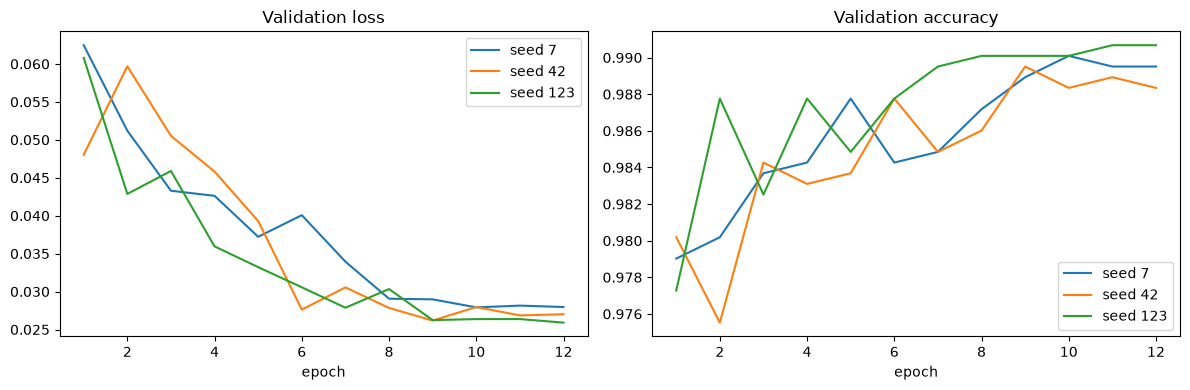

In [11]:
hist_df = pd.DataFrame(all_histories)
if hist_df.empty:
    raise RuntimeError("No training history collected.")

best_seed = int(seed_table.iloc[0]["seed"])
print("best seed by val loss:", best_seed)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for seed in SEEDS:
    h = hist_df[hist_df.seed == seed]
    ax[0].plot(h["epoch"], h["val_loss"], label=f"seed {seed}")
    ax[1].plot(h["epoch"], h["val_acc"], label=f"seed {seed}")
ax[0].set_title("Validation loss")
ax[1].set_title("Validation accuracy")
ax[0].set_xlabel("epoch")
ax[1].set_xlabel("epoch")
ax[0].legend()
ax[1].legend()
plt.tight_layout()
plt.show()


### Step 5 - save summary and canonical best checkpoint

In [12]:
history_path = ARTIFACTS / "fine_tune_history.csv"
seed_table_path = ARTIFACTS / "fine_tune_seed_table.csv"
report_path = ARTIFACTS / "fine_tune_report.json"
canonical_best = ARTIFACTS / "mobilenetv3_finetune_best.pt"

hist_df.to_csv(history_path, index=False)
seed_table.to_csv(seed_table_path, index=False)

best_row = seed_table.iloc[0].to_dict()
shutil.copy2(Path(best_row["best_checkpoint"]), canonical_best)

report = {
    "seeds": SEEDS,
    "epochs_max": EPOCHS,
    "patience": PATIENCE,
    "unfreeze_last_blocks": UNFREEZE_LAST_BLOCKS,
    "backbone_lr": BACKBONE_LR,
    "head_lr": HEAD_LR,
    "imbalance_mode": IMBALANCE_MODE,
    "class_weights": class_weights_np.tolist(),
    "best_run": {
        "seed": int(best_row["seed"]),
        "best_epoch": int(best_row["best_epoch"]),
        "best_val_loss": float(best_row["best_val_loss"]),
        "val_acc": float(best_row["val_acc"]),
        "test_loss": float(best_row["test_loss"]),
        "test_acc": float(best_row["test_acc"]),
        "checkpoint": str(canonical_best),
    },
    "seed_rows": seed_table.to_dict(orient="records"),
}
report_path.write_text(json.dumps(report, indent=2), encoding="utf-8")

print("saved", history_path)
print("saved", seed_table_path)
print("saved", report_path)
print("saved", canonical_best)
print(json.dumps(report["best_run"], indent=2))


saved C:\Users\baabyface\Documents\my work\agrilens\agrilens-training\artifacts\fine_tune_history.csv
saved C:\Users\baabyface\Documents\my work\agrilens\agrilens-training\artifacts\fine_tune_seed_table.csv
saved C:\Users\baabyface\Documents\my work\agrilens\agrilens-training\artifacts\fine_tune_report.json
saved C:\Users\baabyface\Documents\my work\agrilens\agrilens-training\artifacts\mobilenetv3_finetune_best.pt
{
  "seed": 123,
  "best_epoch": 12,
  "best_val_loss": 0.025906379482849188,
  "val_acc": 0.9906759906759907,
  "test_loss": 0.02911509823457751,
  "test_acc": 0.9912485414235706,
  "checkpoint": "C:\\Users\\baabyface\\Documents\\my work\\agrilens\\agrilens-training\\artifacts\\mobilenetv3_finetune_best.pt"
}
